In [ ]:
Round 2: EDA and Feature Engineering

In [1]:

from google.colab import files
uploaded = files.upload()


Saving TransGlobe_Shipment_Delay_Synthetic_Dataset.zip to TransGlobe_Shipment_Delay_Synthetic_Dataset.zip


In [2]:

import zipfile
import pandas as pd
from pathlib import Path

zip_path = next(iter(uploaded.keys()))

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall("/content/transglobe_data")

data_dir = Path("/content/transglobe_data")

shipments = pd.read_csv(
    data_dir / "shipments.csv",
    parse_dates=[
        "dispatch_datetime",
        "promised_delivery_date",
        "actual_delivery_date"
    ]
)

routes = pd.read_csv(data_dir / "routes.csv")
carriers = pd.read_csv(data_dir / "carriers.csv")
events = pd.read_csv(
    data_dir / "events.csv",
    parse_dates=["event_datetime"]
)
weather = pd.read_csv(
    data_dir / "weather.csv",
    parse_dates=["weather_date"]
)

for name, df in {
    "Shipments": shipments,
    "Routes": routes,
    "Carriers": carriers,
    "Events": events,
    "Weather": weather
}.items():
    print(f"{name}: {df.shape}")
    display(df.head(3))


Shipments: (20200, 22)


,shipment_id,route_id,route_name,origin,destination,dispatch_datetime,promised_delivery_date,actual_delivery_date,carrier_id,carrier_name,...,weight_kg,priority,distance_km,planned_transit_hours,actual_transit_hours,hub_count,weather_risk_score,hub_exception_flag,is_delayed,delivery_status
0,TG007052,R032,Bhopal - Chennai,Bhopal,Chennai,2024-03-24 20:31:00,2024-03-26 20:31:00,2024-03-27 20:31:00,C04,TransNational Freight,...,6.85,Low,430,35.20,57.93,2,0.191,1,1.0,Delayed
1,TG014020,R034,Chennai - Lucknow,Chennai,Lucknow,2025-08-17 19:22:00,2025-08-19 19:22:00,2025-08-18 19:22:00,C07,RoadRunner Cargo,...,4.46,High,450,38.37,19.36,2,0.285,0,0.0,On Time
2,TG013996,R023,Kochi - Nagpur,Kochi,Nagpur,2025-08-03 13:34:00,2025-08-06 13:34:00,2025-08-06 13:34:00,C07,RoadRunner Cargo,...,3.94,High,908,53.77,64.84,3,0.247,1,0.0,On Time


Routes: (40, 10)


,route_id,origin,destination,distance_km,route_type,hub_count,hubs,route_name,origin_state,destination_state
0,R001,Kochi,Madurai,612,Intercity,2,Vijayawada > Delhi,Kochi - Madurai,Kerala,Tamil Nadu
1,R002,Chennai,Visakhapatnam,310,Regional,0,Direct,Chennai - Visakhapatnam,Tamil Nadu,Andhra Pradesh
2,R003,Surat,Madurai,1026,Long-haul,3,Bhopal > Kolkata > Hyderabad,Surat - Madurai,Gujarat,Tamil Nadu


Carriers: (8, 5)


,carrier_id,carrier_name,service_level,transit_multiplier,delay_risk_multiplier
0,C01,SwiftShip,Express,0.85,1.00
1,C02,NorthStar Logistics,Standard,1.10,1.10
2,C03,BlueDartway,Express,0.90,0.95


Events: (72219, 10)


,event_id,shipment_id,event_type,hub,event_datetime,exception_code,wait_hours,transit_duration_hours,event_status,carrier_name
0,EV0000001_01,TG000001,Origin Departure,Chennai,2025-03-15 18:19:00,NaN,0.84,1.09,Completed,RoadRunner Cargo
1,EV0000001_H1,TG000001,Hub Arrival,Ahmedabad,2025-03-16 07:11:50,NaN,0.15,3.93,Completed,RoadRunner Cargo
2,EV0000001_DLV,TG000001,Delivered,Indore,2025-03-18 08:19:00,NaN,0.15,45.16,Completed,RoadRunner Cargo


Weather: (14720, 7)


,weather_id,hub,weather_date,rainfall_mm,visibility_km,storm_flag,weather_condition
0,W0000001,Chennai,2024-01-01,0.29,5.38,0,Clear
1,W0000002,Chennai,2024-01-02,2.12,7.88,0,Clear
2,W0000003,Chennai,2024-01-03,2.04,4.34,0,Clear


Load and understand the data

In [3]:

import pandas as pd
from pathlib import Path

data_dir = Path("/content/transglobe_data")

files = {
    "shipments": "shipments.csv",
    "routes": "routes.csv",
    "carriers": "carriers.csv",
    "events": "events.csv",
    "weather": "weather.csv"
}

data = {
    name: pd.read_csv(data_dir / filename)
    for name, filename in files.items()
}

for name, df in data.items():
    print(f"\n{'='*50}")
    print(f"DATASET: {name.upper()}")
    print("Shape:", df.shape)
    print("\nColumns:")
    print(df.columns.tolist())
    print("\nFirst 5 records:")
    display(df.head())



DATASET: SHIPMENTS
Shape: (20200, 22)

Columns:
['shipment_id', 'route_id', 'route_name', 'origin', 'destination', 'dispatch_datetime', 'promised_delivery_date', 'actual_delivery_date', 'carrier_id', 'carrier_name', 'service_level', 'shipment_type', 'weight_kg', 'priority', 'distance_km', 'planned_transit_hours', 'actual_transit_hours', 'hub_count', 'weather_risk_score', 'hub_exception_flag', 'is_delayed', 'delivery_status']

First 5 records:


,shipment_id,route_id,route_name,origin,destination,dispatch_datetime,promised_delivery_date,actual_delivery_date,carrier_id,carrier_name,...,weight_kg,priority,distance_km,planned_transit_hours,actual_transit_hours,hub_count,weather_risk_score,hub_exception_flag,is_delayed,delivery_status
0,TG007052,R032,Bhopal - Chennai,Bhopal,Chennai,2024-03-24 20:31:00,2024-03-26 20:31:00,2024-03-27 20:31:00,C04,TransNational Freight,...,6.85,Low,430,35.20,57.93,2,0.191,1,1.0,Delayed
1,TG014020,R034,Chennai - Lucknow,Chennai,Lucknow,2025-08-17 19:22:00,2025-08-19 19:22:00,2025-08-18 19:22:00,C07,RoadRunner Cargo,...,4.46,High,450,38.37,19.36,2,0.285,0,0.0,On Time
2,TG013996,R023,Kochi - Nagpur,Kochi,Nagpur,2025-08-03 13:34:00,2025-08-06 13:34:00,2025-08-06 13:34:00,C07,RoadRunner Cargo,...,3.94,High,908,53.77,64.84,3,0.247,1,0.0,On Time
3,TG009139,R018,Bhopal - Vijayawada,Bhopal,Vijayawada,2024-05-02 12:45:00,2024-05-05 12:45:00,2024-05-06 12:45:00,C02,NorthStar Logistics,...,23.38,Critical,1614,67.34,86.31,3,0.600,0,1.0,Delayed
4,TG006381,R037,Vijayawada - Pune,Vijayawada,Pune,2025-04-04 11:10:00,2025-04-07 11:10:00,2025-04-07 11:10:00,C04,TransNational Freight,...,17.70,Normal,1279,57.80,49.08,1,0.550,0,0.0,On Time



DATASET: ROUTES
Shape: (40, 10)

Columns:
['route_id', 'origin', 'destination', 'distance_km', 'route_type', 'hub_count', 'hubs', 'route_name', 'origin_state', 'destination_state']

First 5 records:


,route_id,origin,destination,distance_km,route_type,hub_count,hubs,route_name,origin_state,destination_state
0,R001,Kochi,Madurai,612,Intercity,2,Vijayawada > Delhi,Kochi - Madurai,Kerala,Tamil Nadu
1,R002,Chennai,Visakhapatnam,310,Regional,0,Direct,Chennai - Visakhapatnam,Tamil Nadu,Andhra Pradesh
2,R003,Surat,Madurai,1026,Long-haul,3,Bhopal > Kolkata > Hyderabad,Surat - Madurai,Gujarat,Tamil Nadu
3,R004,Visakhapatnam,Surat,592,Intercity,2,Jaipur > Pune,Visakhapatnam - Surat,Andhra Pradesh,Gujarat
4,R005,Bengaluru,Jaipur,135,Regional,1,Indore,Bengaluru - Jaipur,Karnataka,Rajasthan



DATASET: CARRIERS
Shape: (8, 5)

Columns:
['carrier_id', 'carrier_name', 'service_level', 'transit_multiplier', 'delay_risk_multiplier']

First 5 records:


,carrier_id,carrier_name,service_level,transit_multiplier,delay_risk_multiplier
0,C01,SwiftShip,Express,0.85,1.00
1,C02,NorthStar Logistics,Standard,1.10,1.10
2,C03,BlueDartway,Express,0.90,0.95
3,C04,TransNational Freight,Economy,1.30,1.25
4,C05,QuickRoute,Standard,1.00,1.00



DATASET: EVENTS
Shape: (72219, 10)

Columns:
['event_id', 'shipment_id', 'event_type', 'hub', 'event_datetime', 'exception_code', 'wait_hours', 'transit_duration_hours', 'event_status', 'carrier_name']

First 5 records:


,event_id,shipment_id,event_type,hub,event_datetime,exception_code,wait_hours,transit_duration_hours,event_status,carrier_name
0,EV0000001_01,TG000001,Origin Departure,Chennai,2025-03-15 18:19:00,NaN,0.84,1.09,Completed,RoadRunner Cargo
1,EV0000001_H1,TG000001,Hub Arrival,Ahmedabad,2025-03-16 07:11:50,NaN,0.15,3.93,Completed,RoadRunner Cargo
2,EV0000001_DLV,TG000001,Delivered,Indore,2025-03-18 08:19:00,NaN,0.15,45.16,Completed,RoadRunner Cargo
3,EV0000002_01,TG000002,Origin Departure,Coimbatore,2024-05-04 18:01:00,NaN,1.21,0.22,Completed,RoadRunner Cargo
4,EV0000002_H1,TG000002,Hub Arrival,Kolkata,2024-05-05 15:14:33,NaN,0.04,3.10,Completed,RoadRunner Cargo



DATASET: WEATHER
Shape: (14720, 7)

Columns:
['weather_id', 'hub', 'weather_date', 'rainfall_mm', 'visibility_km', 'storm_flag', 'weather_condition']

First 5 records:


,weather_id,hub,weather_date,rainfall_mm,visibility_km,storm_flag,weather_condition
0,W0000001,Chennai,2024-01-01,0.29,5.38,0,Clear
1,W0000002,Chennai,2024-01-02,2.12,7.88,0,Clear
2,W0000003,Chennai,2024-01-03,2.04,4.34,0,Clear
3,W0000004,Chennai,2024-01-04,2.86,6.88,0,Clear
4,W0000005,Chennai,2024-01-05,1.97,8.93,0,Clear


Check data quality

In [4]:

for name, df in data.items():
    print(f"\n{'='*50}")
    print(f"DATA QUALITY REPORT: {name.upper()}")

    print("\nData types:")
    print(df.dtypes)

    print("\nMissing values:")
    missing = df.isnull().sum()
    print(missing[missing > 0].sort_values(ascending=False))

    print("\nDuplicate rows:", df.duplicated().sum())

    if "shipment_id" in df.columns:
        print(
            "Duplicate shipment IDs:",
            df["shipment_id"].duplicated().sum()
        )

    print("\nNumerical summary:")
    display(df.select_dtypes(include="number").describe().T)



DATA QUALITY REPORT: SHIPMENTS

Data types:
shipment_id                object
route_id                   object
route_name                 object
origin                     object
destination                object
dispatch_datetime          object
promised_delivery_date     object
actual_delivery_date       object
carrier_id                 object
carrier_name               object
service_level              object
shipment_type              object
weight_kg                 float64
priority                   object
distance_km                 int64
planned_transit_hours     float64
actual_transit_hours      float64
hub_count                   int64
weather_risk_score        float64
hub_exception_flag          int64
is_delayed                float64
delivery_status            object
dtype: object

Missing values:
actual_delivery_date    644
actual_transit_hours    644
is_delayed              644
dtype: int64

Duplicate rows: 99
Duplicate shipment IDs: 200

Numerical summary:


,count,mean,std,min,25%,50%,75%,max
weight_kg,20200.0,11.185278,12.778967,0.200000,4.020,7.40,13.6625,339.260000
distance_km,20200.0,895.286584,455.598648,135.000000,592.000,741.00,1375.0000,1688.000000
planned_transit_hours,20200.0,37.777482,13.594533,13.200000,27.800,36.24,46.3500,87.880000
actual_transit_hours,19556.0,43.974744,143.770659,-23.439197,24.820,37.51,51.0900,4962.785884
hub_count,20200.0,1.642178,0.912306,0.000000,1.000,1.00,2.0000,3.000000
weather_risk_score,20200.0,0.264747,0.158079,0.001000,0.142,0.24,0.3660,0.924000
hub_exception_flag,20200.0,0.145495,0.352608,0.000000,0.000,0.00,0.0000,1.000000
is_delayed,19556.0,0.216404,0.411803,0.000000,0.000,0.00,0.0000,1.000000



DATA QUALITY REPORT: ROUTES

Data types:
route_id             object
origin               object
destination          object
distance_km           int64
route_type           object
hub_count             int64
hubs                 object
route_name           object
origin_state         object
destination_state    object
dtype: object

Missing values:
Series([], dtype: int64)

Duplicate rows: 0

Numerical summary:


,count,mean,std,min,25%,50%,75%,max
distance_km,40.0,893.425,461.216334,135.0,589.0,755.0,1350.25,1688.0
hub_count,40.0,1.650,0.921259,0.0,1.0,1.5,2.00,3.0



DATA QUALITY REPORT: CARRIERS

Data types:
carrier_id                object
carrier_name              object
service_level             object
transit_multiplier       float64
delay_risk_multiplier    float64
dtype: object

Missing values:
Series([], dtype: int64)

Duplicate rows: 0

Numerical summary:


,count,mean,std,min,25%,50%,75%,max
transit_multiplier,8.0,1.00,0.198494,0.78,0.8425,0.95,1.1375,1.30
delay_risk_multiplier,8.0,1.04,0.130165,0.90,0.9425,1.00,1.1250,1.25



DATA QUALITY REPORT: EVENTS

Data types:
event_id                   object
shipment_id                object
event_type                 object
hub                        object
event_datetime             object
exception_code             object
wait_hours                float64
transit_duration_hours    float64
event_status               object
carrier_name               object
dtype: object

Missing values:
exception_code    68463
dtype: int64

Duplicate rows: 0
Duplicate shipment IDs: 52219

Numerical summary:


,count,mean,std,min,25%,50%,75%,max
wait_hours,72219.0,0.723145,0.982908,0.000000,0.16,0.41,0.900,22.710000
transit_duration_hours,72219.0,13.005554,35.550958,-11.850037,1.37,3.48,13.845,1991.137321



DATA QUALITY REPORT: WEATHER

Data types:
weather_id            object
hub                   object
weather_date          object
rainfall_mm          float64
visibility_km        float64
storm_flag             int64
weather_condition     object
dtype: object

Missing values:
Series([], dtype: int64)

Duplicate rows: 0

Numerical summary:


,count,mean,std,min,25%,50%,75%,max
rainfall_mm,14720.0,2.494787,3.489738,0.0,0.18,1.26,3.28,35.84
visibility_km,14720.0,6.930538,1.465802,0.3,6.08,7.04,7.92,10.00
storm_flag,14720.0,0.049049,0.215978,0.0,0.00,0.00,0.00,1.00


Create a safe copy and convert data types

In [5]:

import pandas as pd
import numpy as np

# Preserve original datasets
shipments_raw = data["shipments"].copy()
routes_raw = data["routes"].copy()
carriers_raw = data["carriers"].copy()
events_raw = data["events"].copy()
weather_raw = data["weather"].copy()

# Convert date columns
date_columns = [
    "dispatch_datetime",
    "promised_delivery_date",
    "actual_delivery_date"
]

for col in date_columns:
    shipments_raw[col] = pd.to_datetime(
        shipments_raw[col], errors="coerce"
    )

events_raw["event_datetime"] = pd.to_datetime(
    events_raw["event_datetime"], errors="coerce"
)

weather_raw["weather_date"] = pd.to_datetime(
    weather_raw["weather_date"], errors="coerce"
)

print("Date conversion completed.")

print(shipments_raw[date_columns].dtypes)


Date conversion completed.
dispatch_datetime         datetime64[ns]
promised_delivery_date    datetime64[ns]
actual_delivery_date      datetime64[ns]
dtype: object


Investigate duplicate shipment IDs

In [6]:

duplicate_rows = shipments_raw[
    shipments_raw.duplicated("shipment_id", keep=False)
].sort_values("shipment_id")

print("Rows belonging to duplicated shipment IDs:",
      len(duplicate_rows))

print("Number of duplicated shipment IDs:",
      shipments_raw["shipment_id"].duplicated().sum())

display(duplicate_rows.head(10))


Rows belonging to duplicated shipment IDs: 400
Number of duplicated shipment IDs: 200


,shipment_id,route_id,route_name,origin,destination,dispatch_datetime,promised_delivery_date,actual_delivery_date,carrier_id,carrier_name,...,weight_kg,priority,distance_km,planned_transit_hours,actual_transit_hours,hub_count,weather_risk_score,hub_exception_flag,is_delayed,delivery_status
18146,TG000073,R031,Hyderabad - Madurai,Hyderabad,Madurai,2024-10-25 20:51:00,2024-10-28 20:51:00,2024-10-27 20:51:00,C07,RoadRunner Cargo,...,3.13,High,1450,54.10,40.29,1,0.450,0,0.0,On Time
16075,TG000073,R031,Hyderabad - Madurai,Hyderabad,Madurai,2024-10-25 20:51:00,2024-10-28 20:51:00,2024-10-27 20:51:00,C07,RoadRunner Cargo,...,3.13,Normal,1450,54.10,40.29,1,0.450,0,0.0,On Time
307,TG000301,R022,Coimbatore - Pune,Coimbatore,Pune,2024-12-30 14:30:00,2025-01-01 14:30:00,2025-01-01 14:30:00,C06,AeroParcel,...,6.79,Normal,1375,34.36,45.57,1,0.231,1,0.0,On Time
11409,TG000301,R022,Coimbatore - Pune,Coimbatore,Pune,2024-12-30 14:30:00,2025-01-01 14:30:00,2025-01-01 14:30:00,C06,AeroParcel,...,6.79,Normal,1375,34.36,45.57,1,0.231,1,0.0,On Time
1644,TG000538,R020,Bhopal - Coimbatore,Bhopal,Coimbatore,2024-11-29 09:59:00,2024-12-01 09:59:00,2024-12-02 09:59:00,C07,RoadRunner Cargo,...,12.51,High,580,42.94,57.02,2,0.331,1,1.0,Delayed
12130,TG000538,R020,Bhopal - Coimbatore,Bhopal,Coimbatore,2024-11-29 09:59:00,2024-12-01 09:59:00,2024-12-02 09:59:00,C07,RoadRunner Cargo,...,12.51,High,580,42.94,57.02,2,0.331,1,1.0,Delayed
18955,TG000567,R007,Hyderabad - Kolkata,Hyderabad,Kolkata,2025-03-11 15:27:00,2025-03-12 15:27:00,2025-03-12 15:27:00,C01,SwiftShip,...,4.32,High,258,21.09,14.20,2,0.232,0,0.0,On Time
4777,TG000567,R007,Hyderabad - Kolkata,Hyderabad,Kolkata,2025-03-11 15:27:00,2025-03-12 15:27:00,2025-03-12 15:27:00,C01,SwiftShip,...,4.32,Normal,258,21.09,14.20,2,0.232,0,0.0,On Time
14938,TG000788,R015,Kolkata - Vijayawada,Kolkata,Vijayawada,2024-12-13 23:22:00,2024-12-14 23:22:00,2024-12-14 23:22:00,C08,PrimeTrack,...,26.97,Low,332,14.40,13.03,0,0.316,0,0.0,On Time
19768,TG000788,R015,Kolkata - Vijayawada,Kolkata,Vijayawada,2024-12-13 23:22:00,2024-12-14 23:22:00,2024-12-14 23:22:00,C08,PrimeTrack,...,26.97,Low,332,14.40,13.03,0,0.316,0,0.0,On Time


Resolve duplicate shipment records

In [7]:

shipments_raw["valid_actual_date"] = (
    shipments_raw["actual_delivery_date"].notna()
)

shipments_raw["valid_transit"] = (
    shipments_raw["actual_transit_hours"].between(0, 240)
)

# Rank records: prefer known delivery dates and valid transit durations
shipments_clean = (
    shipments_raw
    .sort_values(
        ["valid_actual_date", "valid_transit"],
        ascending=False
    )
    .drop_duplicates("shipment_id", keep="first")
    .copy()
)

shipments_clean.drop(
    columns=["valid_actual_date", "valid_transit"],
    inplace=True
)

print("Rows before cleaning:", len(shipments_raw))
print("Rows after resolving duplicate IDs:", len(shipments_clean))
print("Remaining duplicate IDs:",
      shipments_clean["shipment_id"].duplicated().sum())


Rows before cleaning: 20200
Rows after resolving duplicate IDs: 20000
Remaining duplicate IDs: 0


Clean transit durations

In [8]:

# Identify invalid transit durations
invalid_transit = ~shipments_clean["actual_transit_hours"].between(
    0, 240
)

print("Invalid transit durations:",
      invalid_transit.sum())

# Replace invalid values with NaN
shipments_clean.loc[
    invalid_transit, "actual_transit_hours"
] = np.nan

print("Invalid values remaining:",
      (~shipments_clean["actual_transit_hours"].between(0, 240)).sum())


Invalid transit durations: 690
Invalid values remaining: 690


Standardize route names

In [9]:

def standardize_route_name(value):
    if pd.isna(value):
        return np.nan

    value = str(value).strip().upper()
    value = value.replace(" TO ", " - ")
    value = " - ".join(
        part.strip() for part in value.split("-")
    )
    return value

shipments_clean["route_name"] = (
    shipments_clean["route_name"].apply(standardize_route_name)
)

routes_raw["route_name"] = (
    routes_raw["route_name"].apply(standardize_route_name)
)

print("Sample standardized shipment routes:")
display(shipments_clean[["route_id", "route_name"]].head(10))


Sample standardized shipment routes:


,route_id,route_name
0,R032,BHOPAL - CHENNAI
1,R034,CHENNAI - LUCKNOW
2,R023,KOCHI - NAGPUR
3,R018,BHOPAL - VIJAYAWADA
4,R037,VIJAYAWADA - PUNE
5,R028,BHOPAL - MYSURU
6,R010,MYSURU - MADURAI
7,R018,BHOPAL - VIJAYAWADA
8,R018,BHOPAL - VIJAYAWADA
9,R014,HYDERABAD - CHENNAI


Handle incomplete exception codes

In [10]:

events_clean = events_raw.copy()

exception_mask = events_clean["event_status"].eq("Exception")

missing_exception_codes = (
    exception_mask & events_clean["exception_code"].isna()
)

print("Exception records with missing codes:",
      missing_exception_codes.sum())

events_clean.loc[
    missing_exception_codes, "exception_code"
] = "UNKNOWN_EXCEPTION"

# Validate event transit durations
invalid_event_duration = ~events_clean[
    "transit_duration_hours"
].between(0, 240)

print("Invalid event transit durations:",
      invalid_event_duration.sum())

events_clean.loc[
    invalid_event_duration, "transit_duration_hours"
] = np.nan

print("Exception-code cleaning completed.")


Exception records with missing codes: 512
Invalid event transit durations: 387
Exception-code cleaning completed.


Review the cleaned shipment data

In [11]:

print("Cleaned shipment shape:", shipments_clean.shape)

print("\nMissing values:")
display(
    shipments_clean.isna().sum()
    .sort_values(ascending=False)
    .to_frame("missing_count")
    .query("missing_count > 0")
)

print("\nTransit duration summary:")
display(shipments_clean["actual_transit_hours"].describe())

print("\nDelivery status counts:")
display(shipments_clean["delivery_status"].value_counts(dropna=False))


Cleaned shipment shape: (20000, 22)

Missing values:


,missing_count
actual_transit_hours,690
actual_delivery_date,640
is_delayed,640



Transit duration summary:


,actual_transit_hours
count,19310.000000
mean,39.033982
std,18.244110
min,4.000000
25%,24.850000
50%,37.500000
75%,51.067500
max,120.590000



Delivery status counts:


,count
delivery_status,
On Time,15161
Delayed,4199
Unknown,640


Prepare route and carrier data

In [12]:

# Start with the cleaned reference datasets
routes_clean = routes_raw.copy()
carriers_clean = carriers_raw.copy()

# Remove duplicate reference IDs if any
routes_clean = routes_clean.drop_duplicates(
    subset="route_id", keep="first"
)
carriers_clean = carriers_clean.drop_duplicates(
    subset="carrier_id", keep="first"
)

# Keep route columns needed for analysis
route_columns = [
    "route_id", "distance_km", "route_type",
    "hub_count", "hubs"
]

routes_analysis = routes_clean[route_columns].copy()

# Keep carrier columns needed for analysis
carrier_columns = [
    "carrier_id", "carrier_name",
    "service_level", "transit_multiplier",
    "delay_risk_multiplier"
]

carriers_analysis = carriers_clean[carrier_columns].copy()

print("Routes:", routes_analysis.shape)
print("Carriers:", carriers_analysis.shape)


Routes: (40, 5)
Carriers: (8, 5)


Aggregate hub events by shipment

In [13]:

events_work = events_clean.copy()

# Create a reliable exception indicator
events_work["has_exception"] = (
    events_work["event_status"].eq("Exception").astype(int)
)

events_work["has_exception_code"] = (
    events_work["exception_code"].notna()
    & events_work["exception_code"].ne("UNKNOWN_EXCEPTION")
).astype(int)

# Aggregate events to one row per shipment
event_summary = (
    events_work.groupby("shipment_id")
    .agg(
        total_events=("event_id", "count"),
        exception_events=("has_exception", "sum"),
        coded_exceptions=("has_exception_code", "sum"),
        total_wait_hours=("wait_hours", "sum"),
        avg_event_transit_hours=(
            "transit_duration_hours", "mean"
        )
    )
    .reset_index()
)

event_summary["has_hub_exception"] = (
    event_summary["exception_events"] > 0
).astype(int)

print("Aggregated event data:", event_summary.shape)
display(event_summary.head())


Aggregated event data: (20000, 7)


,shipment_id,total_events,exception_events,coded_exceptions,total_wait_hours,avg_event_transit_hours,has_hub_exception
0,TG000001,3,0,0,1.14,16.726667,0
1,TG000002,2,0,0,1.25,1.660000,0
2,TG000003,3,0,0,1.51,14.473333,0
3,TG000004,5,0,0,1.65,12.272000,0
4,TG000005,5,2,2,13.28,14.400000,1


Aggregate weather by shipment

In [14]:

# Extract event date for matching
weather_work = weather_raw.copy()
weather_work["weather_date"] = pd.to_datetime(
    weather_work["weather_date"], errors="coerce"
).dt.normalize()

events_weather = events_work.copy()
events_weather["event_date"] = pd.to_datetime(
    events_weather["event_datetime"], errors="coerce"
).dt.normalize()

# Join events to daily weather by hub and date
events_weather = events_weather.merge(
    weather_work[
        ["hub", "weather_date", "rainfall_mm",
         "visibility_km", "storm_flag"]
    ],
    left_on=["hub", "event_date"],
    right_on=["hub", "weather_date"],
    how="left",
    validate="many_to_one"
)

# Aggregate weather exposure to one row per shipment
weather_summary = (
    events_weather.groupby("shipment_id")
    .agg(
        avg_rainfall_mm=("rainfall_mm", "mean"),
        max_rainfall_mm=("rainfall_mm", "max"),
        avg_visibility_km=("visibility_km", "mean"),
        storm_exposure=("storm_flag", "max"),
        weather_observations=("rainfall_mm", "count")
    )
    .reset_index()
)

print("Aggregated weather data:", weather_summary.shape)
display(weather_summary.head())


Aggregated weather data: (20000, 6)


,shipment_id,avg_rainfall_mm,max_rainfall_mm,avg_visibility_km,storm_exposure,weather_observations
0,TG000001,1.276667,2.96,7.316667,0,3
1,TG000002,0.000000,0.00,7.865000,0,2
2,TG000003,7.356667,16.60,6.330000,0,3
3,TG000004,0.844000,3.95,6.626000,0,5
4,TG000005,8.024000,12.59,5.584000,1,5


Merge everything into one dataset

In [15]:

# Begin with one row per shipment
merged_df = shipments_clean.copy()

# Merge route information
merged_df = merged_df.merge(
    routes_analysis,
    on="route_id",
    how="left",
    suffixes=("", "_route"),
    validate="many_to_one"
)

# Merge carrier information
merged_df = merged_df.merge(
    carriers_analysis,
    on=["carrier_id", "carrier_name", "service_level"],
    how="left",
    suffixes=("", "_carrier"),
    validate="many_to_one"
)

# Merge aggregated event data
merged_df = merged_df.merge(
    event_summary,
    on="shipment_id",
    how="left",
    validate="one_to_one"
)

# Merge aggregated weather data
merged_df = merged_df.merge(
    weather_summary,
    on="shipment_id",
    how="left",
    validate="one_to_one"
)

print("Final merged dataset shape:", merged_df.shape)
print("Unique shipment IDs:", merged_df["shipment_id"].nunique())
print("Duplicate shipment IDs:",
      merged_df["shipment_id"].duplicated().sum())

display(merged_df.head())


Final merged dataset shape: (20000, 39)
Unique shipment IDs: 20000
Duplicate shipment IDs: 0


,shipment_id,route_id,route_name,origin,destination,dispatch_datetime,promised_delivery_date,actual_delivery_date,carrier_id,carrier_name,...,exception_events,coded_exceptions,total_wait_hours,avg_event_transit_hours,has_hub_exception,avg_rainfall_mm,max_rainfall_mm,avg_visibility_km,storm_exposure,weather_observations
0,TG007052,R032,BHOPAL - CHENNAI,Bhopal,Chennai,2024-03-24 20:31:00,2024-03-26 20:31:00,2024-03-27 20:31:00,C04,TransNational Freight,...,2,2,6.71,17.2150,1,0.4250,1.06,6.520000,0,4
1,TG014020,R034,CHENNAI - LUCKNOW,Chennai,Lucknow,2025-08-17 19:22:00,2025-08-19 19:22:00,2025-08-18 19:22:00,C07,RoadRunner Cargo,...,0,0,0.73,7.3275,0,4.2175,8.04,6.917500,0,4
2,TG013996,R023,KOCHI - NAGPUR,Kochi,Nagpur,2025-08-03 13:34:00,2025-08-06 13:34:00,2025-08-06 13:34:00,C07,RoadRunner Cargo,...,3,2,5.95,15.0580,1,6.7700,16.70,6.116000,0,5
3,TG009139,R018,BHOPAL - VIJAYAWADA,Bhopal,Vijayawada,2024-05-02 12:45:00,2024-05-05 12:45:00,2024-05-06 12:45:00,C02,NorthStar Logistics,...,0,0,6.62,19.0820,0,0.9600,2.50,5.524000,0,5
4,TG006381,R037,VIJAYAWADA - PUNE,Vijayawada,Pune,2025-04-04 11:10:00,2025-04-07 11:10:00,2025-04-07 11:10:00,C04,TransNational Freight,...,0,0,2.66,17.5000,0,2.7400,5.12,5.596667,0,3


Validate the merged dataset

In [16]:

print("Missing values in merged dataset:")
display(
    merged_df.isna().sum()
    .sort_values(ascending=False)
    .to_frame("missing_count")
    .query("missing_count > 0")
)

print("\nDelivery status:")
display(merged_df["delivery_status"].value_counts(dropna=False))

print("\nRoute coverage:",
      merged_df["route_type"].notna().mean() * 100, "%")

print("Carrier coverage:",
      merged_df["transit_multiplier"].notna().mean() * 100, "%")

print("Weather coverage:",
      merged_df["weather_observations"].gt(0).mean() * 100, "%")


Missing values in merged dataset:


,missing_count
actual_transit_hours,690
actual_delivery_date,640
is_delayed,640



Delivery status:


,count
delivery_status,
On Time,15161
Delayed,4199
Unknown,640



Route coverage: 100.0 %
Carrier coverage: 100.0 %
Weather coverage: 100.0 %


Dataset shape: (20000, 39)
Unique shipment IDs: 20000

Feature engineering complete.
Delivery outcomes:
delivery_status
On Time    15161
Delayed     4199
Unknown      640
Name: count, dtype: int64

Data quality report:


,dtype,missing_count,missing_percent,unique_values
shipment_id,object,0,0.00,20000
route_id,object,0,0.00,40
route_name,object,0,0.00,40
origin,object,0,0.00,15
destination,object,0,0.00,17
dispatch_datetime,datetime64[ns],0,0.00,19757
promised_delivery_date,datetime64[ns],0,0.00,19777
actual_delivery_date,datetime64[ns],640,3.20,19133
carrier_id,object,0,0.00,8
carrier_name,object,0,0.00,8



Total shipment records: 20000
Known delivery outcomes: 19360
Unknown delivery outcomes: 640
Overall delay rate among known outcomes: 21.69%

Top 10 routes by delay rate (minimum 30 shipments):


,route_name,shipments,delay_rate,avg_transit_hours,avg_delay_days,delay_rate_pct
36,SURAT - MADURAI,484,0.330579,49.549793,0.243802,33.057851
22,HYDERABAD - KOLKATA,444,0.310811,25.135440,0.157658,31.081081
34,PUNE - SURAT,510,0.300000,55.326412,0.084314,30.000000
26,KOCHI - NAGPUR,450,0.297778,45.835491,0.195556,29.777778
1,BENGALURU - JAIPUR,449,0.289532,17.428591,0.302895,28.953229
18,DELHI - AHMEDABAD,480,0.287500,58.032708,0.085417,28.750000
23,HYDERABAD - MADURAI,453,0.284768,50.591615,0.154525,28.476821
35,SURAT - INDORE,478,0.282427,59.600021,0.098326,28.242678
29,LUCKNOW - HYDERABAD,482,0.282158,22.040705,0.172199,28.215768
9,CHENNAI - AHMEDABAD,497,0.275654,47.024061,0.175050,27.565392



Carrier comparison:


...

,dispatch_period,shipments,delay_rate,avg_transit_hours,avg_delay_days,delay_rate_pct
3,Evening,4910,0.232383,39.856776,0.059878,23.238289
4,Late Night,1922,0.224766,38.646794,0.041103,22.476587
2,Afternoon,5086,0.215100,39.167332,0.017696,21.510028
0,Night,1416,0.211864,38.893678,0.010593,21.186441
1,Morning,6026,0.204447,38.408187,0.011450,20.444739



Hub exception comparison:


,has_hub_exception,shipments,delay_rate,avg_transit_hours,avg_delay_days,delay_rate_pct
1,1,2215,0.272686,45.114267,0.188262,27.268623
0,0,17145,0.209682,38.248168,0.007582,20.968212



Storm exposure comparison:


,has_storm_exposure,shipments,delay_rate,avg_transit_hours,avg_delay_days,delay_rate_pct
0,0,16241,0.217105,38.900754,0.030540,21.710486
1,1,3119,0.215774,39.727173,0.016351,21.577429


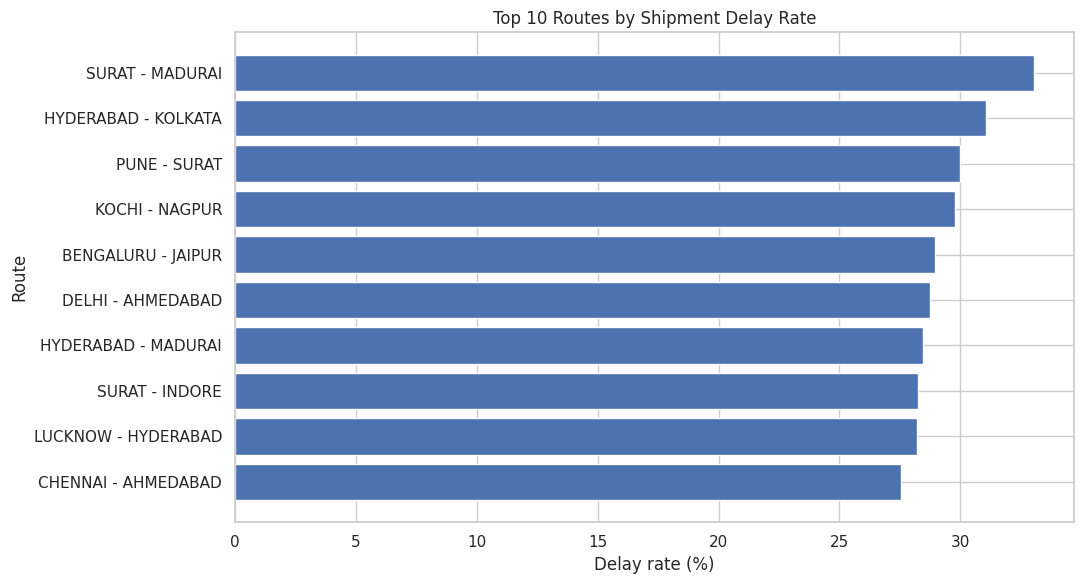

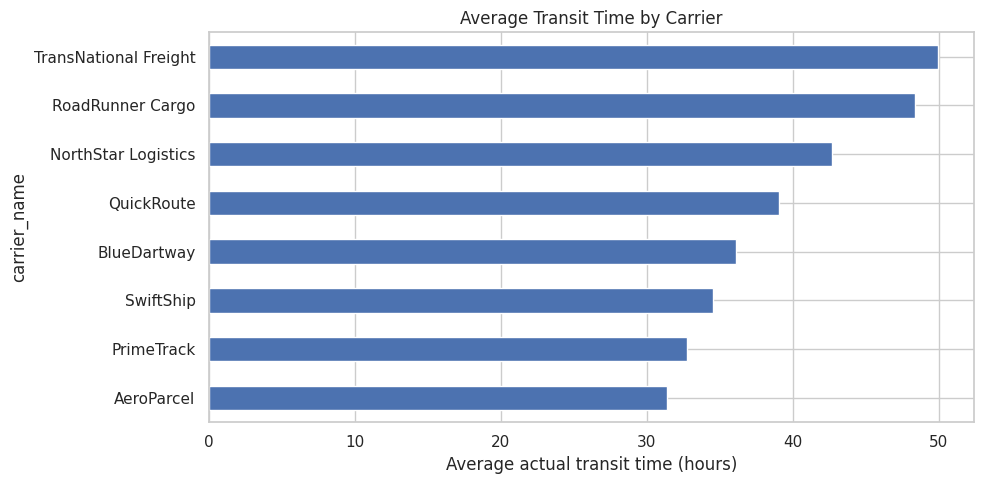

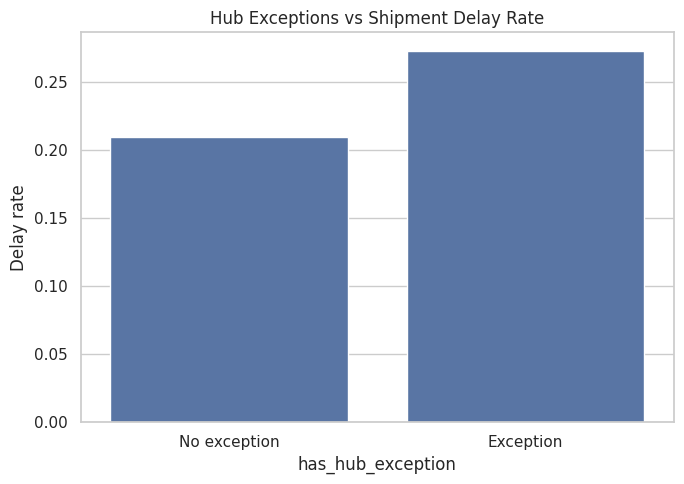

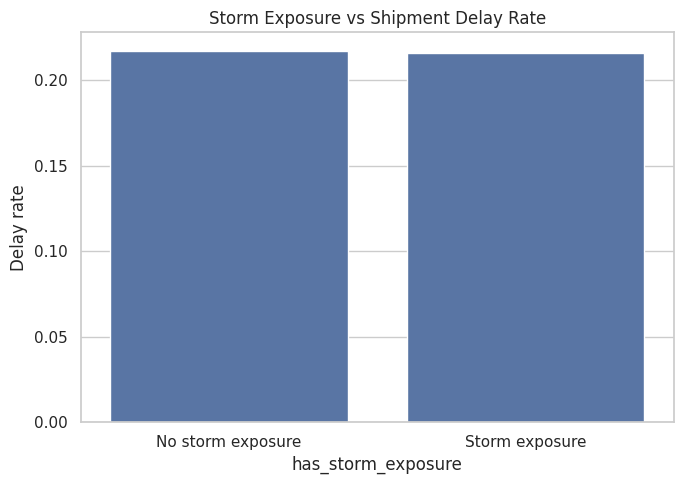

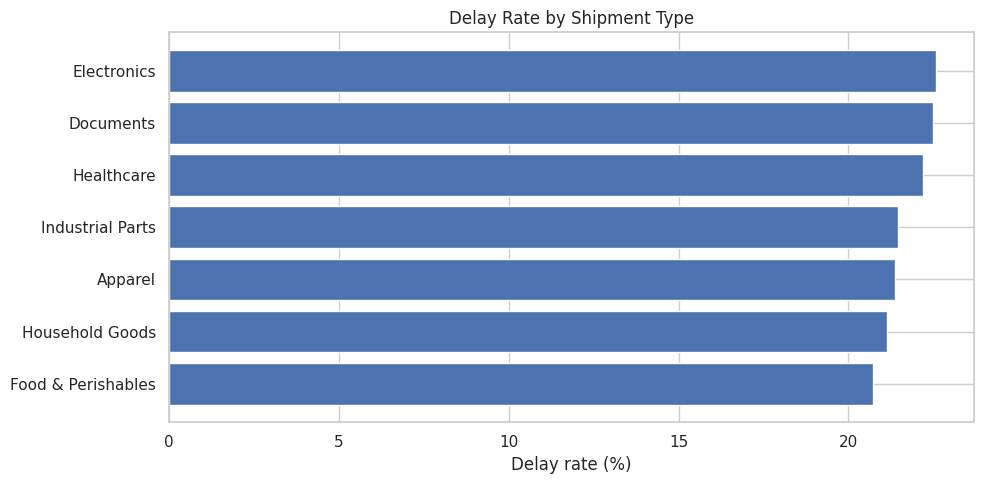

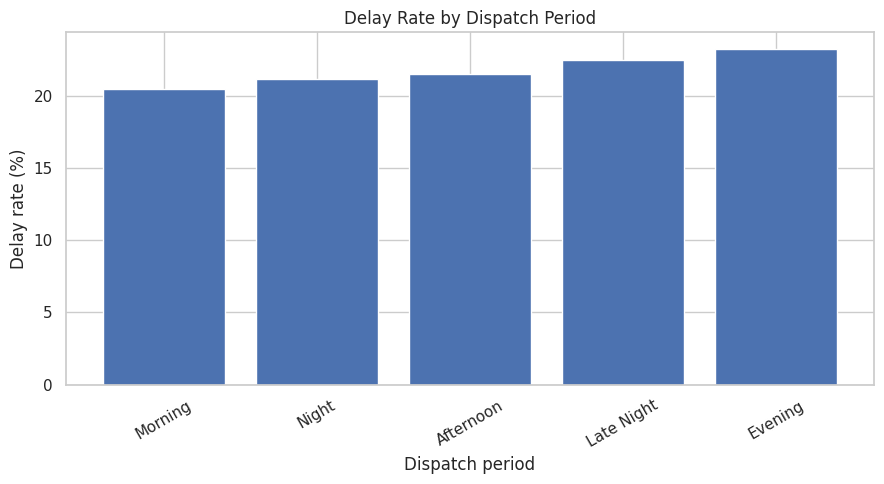

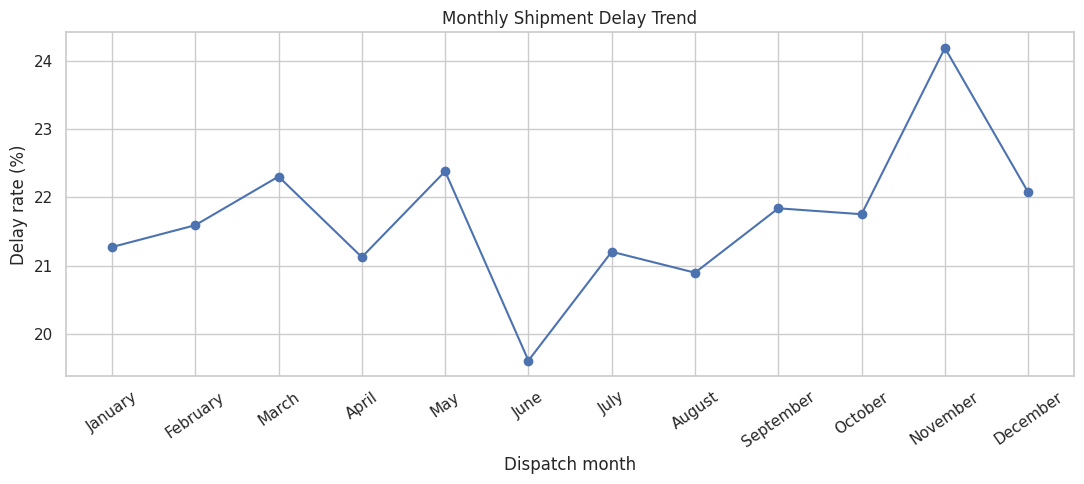

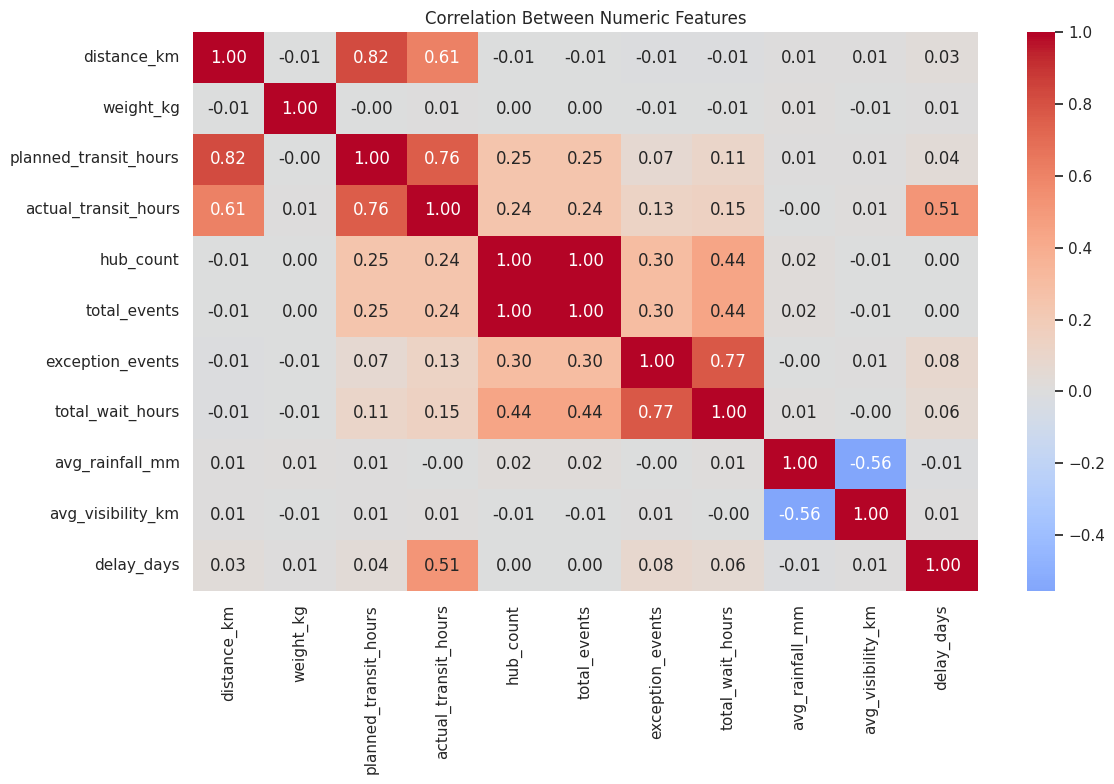


Encoded categorical columns:
['route_type_encoded', 'carrier_name_encoded', 'service_level_encoded', 'shipment_type_encoded', 'priority_encoded', 'dispatch_period_encoded', 'distance_band_encoded', 'weight_band_encoded', 'dispatch_day_encoded']

Top 15 features by mutual information:


,feature,mutual_information
9,avg_event_transit_hours,0.117784
2,planned_transit_hours,0.089202
0,distance_km,0.011824
27,distance_band_encoded,0.011371
21,route_type_encoded,0.009144
26,dispatch_period_encoded,0.008979
10,avg_rainfall_mm,0.008381
22,carrier_name_encoded,0.005243
1,weight_kg,0.004942
13,storm_exposure,0.004840


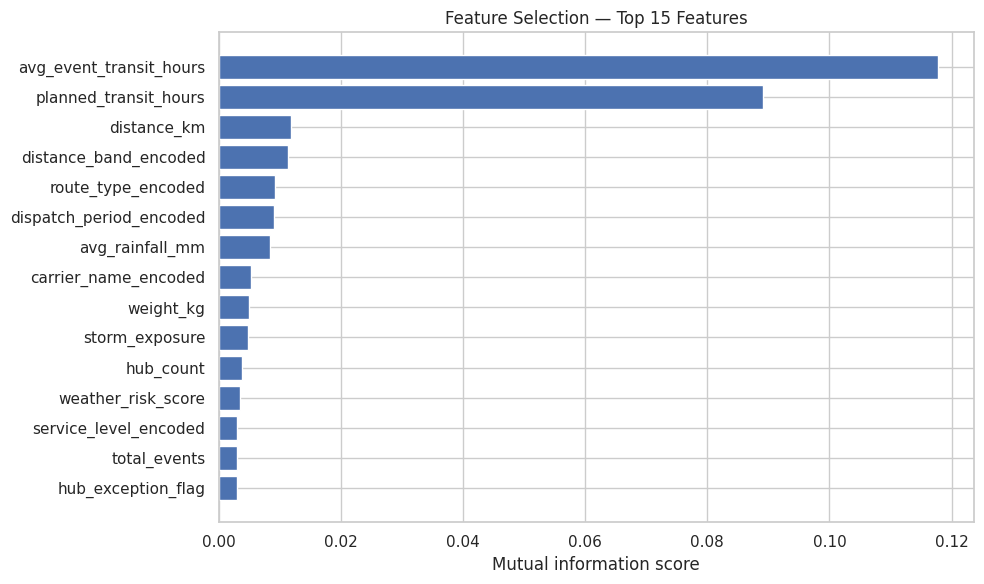


ROUND 2 ANALYSIS COMPLETED.
Output folder: /content/transglobe_outputs
Files created:
- carrier_comparison.csv
- cleaned_shipments_engineered.csv
- data_quality_report.csv
- delay_by_route.csv
- dispatch_period_analysis.csv
- encoded_shipments.csv
- feature_selection.csv
- hub_exception_analysis.csv
- monthly_delay_trend.csv
- round2_analysis_tables.xlsx
- shipment_type_comparison.csv
- weather_impact_analysis.csv


In [17]:

# ============================================================
# TRANSGLOBE LOGISTICS — ROUND 2: EDA & FEATURE ENGINEERING
# ============================================================

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import LabelEncoder

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

# ------------------------------------------------------------
# 1. VALIDATE AND COPY THE MERGED DATASET
# ------------------------------------------------------------

df = merged_df.copy()

df["dispatch_datetime"] = pd.to_datetime(
    df["dispatch_datetime"], errors="coerce"
)
df["promised_delivery_date"] = pd.to_datetime(
    df["promised_delivery_date"], errors="coerce"
)
df["actual_delivery_date"] = pd.to_datetime(
    df["actual_delivery_date"], errors="coerce"
)

df = df.drop_duplicates(subset="shipment_id", keep="first").copy()

print("Dataset shape:", df.shape)
print("Unique shipment IDs:", df["shipment_id"].nunique())

# ------------------------------------------------------------
# 2. FEATURE ENGINEERING
# ------------------------------------------------------------

# Delay in calendar days; only defined for delivered shipments
df["delay_days"] = (
    df["actual_delivery_date"].dt.normalize()
    - df["promised_delivery_date"].dt.normalize()
).dt.days

# Three-class delivery outcome; missing dates remain unknown
df["delivery_status"] = np.select(
    [
        df["actual_delivery_date"].isna()
        | df["promised_delivery_date"].isna(),
        df["delay_days"] > 0
    ],
    ["Unknown", "Delayed"],
    default="On Time"
)

# Binary target for completed delivery outcomes only
df["is_delayed_clean"] = np.where(
    df["delivery_status"].eq("Unknown"),
    np.nan,
    df["delivery_status"].eq("Delayed").astype(int)
)

# Dispatch features
df["dispatch_hour"] = df["dispatch_datetime"].dt.hour
df["dispatch_day"] = df["dispatch_datetime"].dt.day_name()
df["dispatch_month"] = df["dispatch_datetime"].dt.month
df["dispatch_month_name"] = df["dispatch_datetime"].dt.month_name()
df["dispatch_weekday_num"] = df["dispatch_datetime"].dt.dayofweek
df["dispatch_weekend"] = (
    df["dispatch_weekday_num"] >= 5
).astype("Int64")

df["dispatch_period"] = pd.cut(
    df["dispatch_hour"],
    bins=[-1, 5, 11, 16, 20, 23],
    labels=["Night", "Morning", "Afternoon", "Evening", "Late Night"]
)

df["peak_season"] = df["dispatch_month"].isin([11, 12]).astype("Int64")

# Route and shipment features
df["distance_band"] = pd.cut(
    df["distance_km"],
    bins=[0, 400, 1000, np.inf],
    labels=["Short", "Medium", "Long"]
)

df["weight_band"] = pd.cut(
    df["weight_kg"],
    bins=[0, 5, 20, 100, np.inf],
    labels=["Light", "Medium", "Heavy", "Very Heavy"]
)

df["has_hub_exception"] = (
    df["exception_events"].fillna(0) > 0
).astype(int)

df["has_storm_exposure"] = (
    df["storm_exposure"].fillna(0) > 0
).astype(int)

df["low_visibility"] = (
    df["avg_visibility_km"] < 3
).astype("Int64")

df["high_rainfall"] = (
    df["avg_rainfall_mm"] >= 10
).astype("Int64")

df["multiple_hubs"] = (df["hub_count"] >= 2).astype("Int64")

# Avoid using invalid transit values
df.loc[
    ~df["actual_transit_hours"].between(0, 240),
    "actual_transit_hours"
] = np.nan

print("\nFeature engineering complete.")
print("Delivery outcomes:")
print(df["delivery_status"].value_counts(dropna=False))

# ------------------------------------------------------------
# 3. DATA QUALITY SUMMARY
# ------------------------------------------------------------

quality_report = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
    "unique_values": df.nunique(dropna=True)
})

print("\nData quality report:")
display(quality_report)

# ------------------------------------------------------------
# 4. PREPARE DELIVERED-SHIPMENT ANALYSIS DATA
# ------------------------------------------------------------

delivered = df[df["delivery_status"].isin(
    ["On Time", "Delayed"]
)].copy()

print("\nTotal shipment records:", len(df))
print("Known delivery outcomes:", len(delivered))
print("Unknown delivery outcomes:", df["delivery_status"].eq("Unknown").sum())

overall_delay_rate = (
    delivered["delivery_status"].eq("Delayed").mean() * 100
    if len(delivered) else np.nan
)

print(f"Overall delay rate among known outcomes: {overall_delay_rate:.2f}%")

# ------------------------------------------------------------
# 5. SUMMARY TABLES FOR BUSINESS QUESTIONS
# ------------------------------------------------------------

def grouped_delay_summary(data, group_col, min_count=30):
    result = (
        data.groupby(group_col, observed=True, dropna=False)
        .agg(
            shipments=("shipment_id", "nunique"),
            delay_rate=("is_delayed_clean", "mean"),
            avg_transit_hours=("actual_transit_hours", "mean"),
            avg_delay_days=("delay_days", "mean")
        )
        .reset_index()
    )
    result["delay_rate_pct"] = result["delay_rate"] * 100
    result = result[result["shipments"] >= min_count]
    return result.sort_values("delay_rate_pct", ascending=False)

route_summary = grouped_delay_summary(delivered, "route_name")
carrier_summary = grouped_delay_summary(delivered, "carrier_name")
type_summary = grouped_delay_summary(delivered, "shipment_type")
dispatch_summary = grouped_delay_summary(delivered, "dispatch_period")
service_summary = grouped_delay_summary(delivered, "service_level")

exception_summary = grouped_delay_summary(
    delivered, "has_hub_exception", min_count=1
)

weather_summary_table = grouped_delay_summary(
    delivered, "has_storm_exposure", min_count=1
)

print("\nTop 10 routes by delay rate (minimum 30 shipments):")
display(route_summary.head(10))

print("\nCarrier comparison:")
display(carrier_summary)

print("\nShipment type comparison:")
display(type_summary)

print("\nDispatch period comparison:")
display(dispatch_summary)

print("\nHub exception comparison:")
display(exception_summary)

print("\nStorm exposure comparison:")
display(weather_summary_table)

# ------------------------------------------------------------
# 6. VISUALIZATIONS
# ------------------------------------------------------------

# Chart 1: Delay rate by route — top 10 routes
if not route_summary.empty:
    plot_data = route_summary.head(10).sort_values("delay_rate_pct")
    plt.figure(figsize=(11, 6))
    plt.barh(plot_data["route_name"].astype(str),
             plot_data["delay_rate_pct"])
    plt.xlabel("Delay rate (%)")
    plt.ylabel("Route")
    plt.title("Top 10 Routes by Shipment Delay Rate")
    plt.tight_layout()
    plt.show()

# Chart 2: Carrier transit time
carrier_transit = (
    delivered.groupby("carrier_name", dropna=False)
    ["actual_transit_hours"].mean().dropna().sort_values()
)
plt.figure(figsize=(10, 5))
carrier_transit.plot(kind="barh")
plt.xlabel("Average actual transit time (hours)")
plt.title("Average Transit Time by Carrier")
plt.tight_layout()
plt.show()

# Chart 3: Hub exceptions and delay rate
plt.figure(figsize=(7, 5))
sns.barplot(
    data=delivered,
    x="has_hub_exception",
    y="is_delayed_clean",
    errorbar=None
)
plt.xticks([0, 1], ["No exception", "Exception"])
plt.ylabel("Delay rate")
plt.title("Hub Exceptions vs Shipment Delay Rate")
plt.tight_layout()
plt.show()

# Chart 4: Weather and delay rate
plt.figure(figsize=(7, 5))
sns.barplot(
    data=delivered,
    x="has_storm_exposure",
    y="is_delayed_clean",
    errorbar=None
)
plt.xticks([0, 1], ["No storm exposure", "Storm exposure"])
plt.ylabel("Delay rate")
plt.title("Storm Exposure vs Shipment Delay Rate")
plt.tight_layout()
plt.show()

# Chart 5: Shipment type comparison
if not type_summary.empty:
    plot_data = type_summary.sort_values("delay_rate_pct")
    plt.figure(figsize=(10, 5))
    plt.barh(plot_data["shipment_type"].astype(str),
             plot_data["delay_rate_pct"])
    plt.xlabel("Delay rate (%)")
    plt.title("Delay Rate by Shipment Type")
    plt.tight_layout()
    plt.show()

# Chart 6: Dispatch period
if not dispatch_summary.empty:
    plot_data = dispatch_summary.sort_values("delay_rate_pct")
    plt.figure(figsize=(9, 5))
    plt.bar(plot_data["dispatch_period"].astype(str),
            plot_data["delay_rate_pct"])
    plt.xlabel("Dispatch period")
    plt.ylabel("Delay rate (%)")
    plt.title("Delay Rate by Dispatch Period")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

# Chart 7: Monthly delay trend
monthly_summary = (
    delivered.groupby("dispatch_month_name", observed=True)
    .agg(
        shipments=("shipment_id", "nunique"),
        delay_rate=("is_delayed_clean", "mean")
    )
    .reset_index()
)
month_order = [
    "January", "February", "March", "April", "May", "June",
    "July", "August", "September", "October", "November", "December"
]
monthly_summary["month_order"] = monthly_summary[
    "dispatch_month_name"
].map({m: i for i, m in enumerate(month_order)})
monthly_summary = monthly_summary.sort_values("month_order")

plt.figure(figsize=(11, 5))
plt.plot(
    monthly_summary["dispatch_month_name"],
    monthly_summary["delay_rate"] * 100,
    marker="o"
)
plt.ylabel("Delay rate (%)")
plt.xlabel("Dispatch month")
plt.title("Monthly Shipment Delay Trend")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

# Chart 8: Numeric correlation heatmap
numeric_cols = [
    "distance_km", "weight_kg", "planned_transit_hours",
    "actual_transit_hours", "hub_count", "total_events",
    "exception_events", "total_wait_hours", "avg_rainfall_mm",
    "avg_visibility_km", "delay_days"
]
numeric_cols = [c for c in numeric_cols if c in delivered.columns]

plt.figure(figsize=(12, 8))
sns.heatmap(
    delivered[numeric_cols].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)
plt.title("Correlation Between Numeric Features")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 7. CATEGORICAL ENCODING
# ------------------------------------------------------------

categorical_cols = [
    "route_type", "carrier_name", "service_level",
    "shipment_type", "priority", "dispatch_period",
    "distance_band", "weight_band", "dispatch_day"
]
categorical_cols = [c for c in categorical_cols if c in df.columns]

encoded_df = df.copy()
label_encoders = {}

for col in categorical_cols:
    encoded_col = col + "_encoded"
    values = encoded_df[col].astype("string").fillna("Unknown")
    encoder = LabelEncoder()
    encoded_df[encoded_col] = encoder.fit_transform(values)
    label_encoders[col] = encoder

print("\nEncoded categorical columns:")
print([c + "_encoded" for c in categorical_cols])

# ------------------------------------------------------------
# 8. FEATURE SELECTION WITH MUTUAL INFORMATION
# ------------------------------------------------------------

# Use only shipments with known delivery outcomes.
# Exclude direct outcome/leakage columns from predictors.
feature_candidates = [
    "distance_km", "weight_kg", "planned_transit_hours",
    "hub_count", "weather_risk_score", "hub_exception_flag",
    "total_events", "exception_events", "total_wait_hours",
    "avg_event_transit_hours", "avg_rainfall_mm",
    "max_rainfall_mm", "avg_visibility_km", "storm_exposure",
    "dispatch_hour", "dispatch_weekday_num", "dispatch_month",
    "peak_season", "multiple_hubs", "low_visibility",
    "high_rainfall"
] + [c + "_encoded" for c in categorical_cols]

feature_candidates = [
    c for c in feature_candidates if c in encoded_df.columns
]

model_data = encoded_df.loc[
    encoded_df["delivery_status"].isin(["On Time", "Delayed"])
].copy()

X = model_data[feature_candidates].replace(
    [np.inf, -np.inf], np.nan
)

# Fill feature missing values with column medians
X = X.apply(pd.to_numeric, errors="coerce")
X = X.fillna(X.median()).fillna(0)

y = model_data["delivery_status"].eq("Delayed").astype(int)

mi_scores = mutual_info_classif(
    X, y, random_state=42
)

feature_selection = pd.DataFrame({
    "feature": X.columns,
    "mutual_information": mi_scores
}).sort_values("mutual_information", ascending=False)

print("\nTop 15 features by mutual information:")
display(feature_selection.head(15))

plt.figure(figsize=(10, 6))
top_features = feature_selection.head(15).sort_values(
    "mutual_information"
)
plt.barh(top_features["feature"],
         top_features["mutual_information"])
plt.xlabel("Mutual information score")
plt.title("Feature Selection — Top 15 Features")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 9. EXPORT CLEANED DATA AND ANALYSIS TABLES
# ------------------------------------------------------------

output_dir = "/content/transglobe_outputs"
os.makedirs(output_dir, exist_ok=True)

# Main shipment-level data, including engineered features
df.to_csv(
    f"{output_dir}/cleaned_shipments_engineered.csv",
    index=False
)

# Encoded dataset and analysis tables
encoded_df.to_csv(
    f"{output_dir}/encoded_shipments.csv",
    index=False
)

quality_report.to_csv(
    f"{output_dir}/data_quality_report.csv"
)

route_summary.to_csv(
    f"{output_dir}/delay_by_route.csv", index=False
)
carrier_summary.to_csv(
    f"{output_dir}/carrier_comparison.csv", index=False
)
type_summary.to_csv(
    f"{output_dir}/shipment_type_comparison.csv", index=False
)
dispatch_summary.to_csv(
    f"{output_dir}/dispatch_period_analysis.csv", index=False
)
exception_summary.to_csv(
    f"{output_dir}/hub_exception_analysis.csv", index=False
)
weather_summary_table.to_csv(
    f"{output_dir}/weather_impact_analysis.csv", index=False
)
monthly_summary.to_csv(
    f"{output_dir}/monthly_delay_trend.csv", index=False
)
feature_selection.to_csv(
    f"{output_dir}/feature_selection.csv", index=False
)

# Save one Excel-friendly workbook with tables on separate sheets
with pd.ExcelWriter(
    f"{output_dir}/round2_analysis_tables.xlsx",
    engine="openpyxl"
) as writer:
    quality_report.to_excel(writer, sheet_name="Data Quality")
    route_summary.to_excel(writer, sheet_name="Route Delays", index=False)
    carrier_summary.to_excel(writer, sheet_name="Carrier Analysis", index=False)
    type_summary.to_excel(writer, sheet_name="Shipment Types", index=False)
    dispatch_summary.to_excel(writer, sheet_name="Dispatch Period", index=False)
    exception_summary.to_excel(writer, sheet_name="Hub Exceptions", index=False)
    weather_summary_table.to_excel(writer, sheet_name="Weather Impact", index=False)
    monthly_summary.to_excel(writer, sheet_name="Monthly Trend", index=False)
    feature_selection.to_excel(writer, sheet_name="Feature Selection", index=False)

print("\nROUND 2 ANALYSIS COMPLETED.")
print("Output folder:", output_dir)
print("Files created:")
for filename in sorted(os.listdir(output_dir)):
    print("-", filename)


In [18]:
from google.colab import files

files.download(
    "/content/transglobe_outputs/round2_analysis_tables.xlsx"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [19]:
files.download(
    "/content/transglobe_outputs/cleaned_shipments_engineered.csv"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>